# 02 — Probability and Multimodality

In the previous notebook, we trained a deterministic Behavior Cloning policy:

$$
\hat a = \pi_\theta(o)
$$

using Mean Squared Error.

However, our expert dataset contains two valid strategies for the same task:
going left or right around an obstacle.

A deterministic policy can only predict one action for each observation.

We now change perspective:

Instead of learning a single action, we want to understand the distribution

$$
p(a \mid o)
$$

which describes which actions are plausible given an observation.

This notebook introduces the probability concepts needed to understand
modern generative robot policies.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from robot_learning_playground.point_robot import (
    collect_demonstrations,
    left_expert,
    right_expert,
)

demonstrations = collect_demonstrations(
    n_episodes=500,
    seed=42,
)

Lets consider a precise observation $o^*=[0,0,0,1]$ and the output for the experts:

In [2]:
position = np.array([0.0, 0.0])
goal = np.array([0.0, 1.0])

a_left = left_expert(position, goal)
a_right = right_expert(position, goal)

print("Left: ", a_left)
print("Right:", a_right)

Left:  [-0.02867312  0.0409616 ]
Right: [0.02867312 0.0409616 ]


(1000, 2)


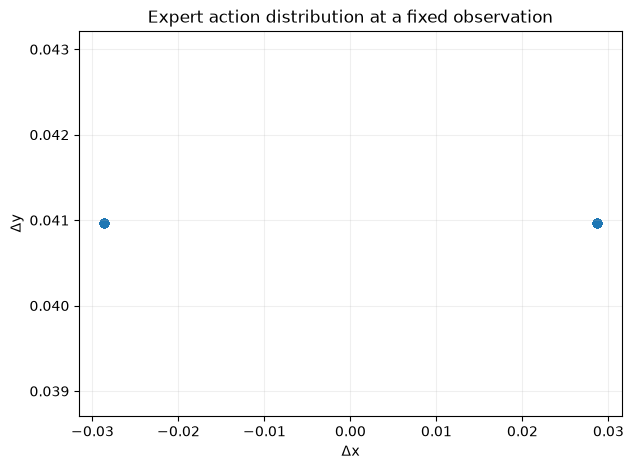

In [3]:
rng = np.random.default_rng(42)

n_samples = 1000

expert_actions = np.stack([
    a_left if rng.random() < 0.5 else a_right
    for _ in range(n_samples)
])

print(expert_actions.shape)

plt.figure(figsize=(7, 5))

plt.scatter(
    expert_actions[:, 0],
    expert_actions[:, 1],
    alpha=0.15,
)

plt.xlabel("Δx")
plt.ylabel("Δy")
plt.title("Expert action distribution at a fixed observation")
plt.grid(alpha=0.2)
plt.show()

Mean action: [-0.00017204  0.0409616 ]


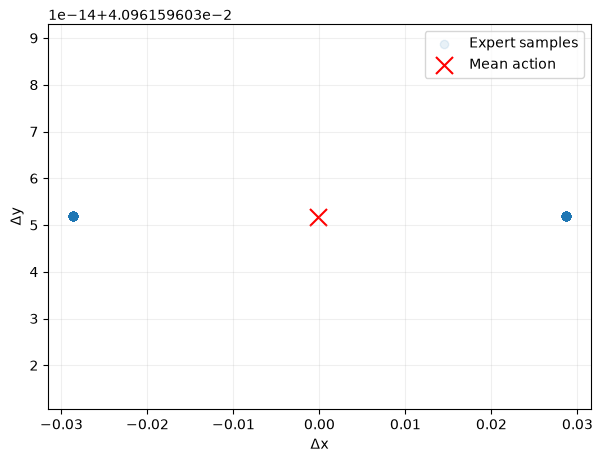

In [5]:
mean_action = expert_actions.mean(axis=0)

print("Mean action:", mean_action)

plt.figure(figsize=(7, 5))

plt.scatter(
    expert_actions[:, 0],
    expert_actions[:, 1],
    alpha=0.1,
    label="Expert samples",
)

plt.scatter(
    *mean_action,
    color="red",
    marker="x",
    s=150,
    label="Mean action",
)

plt.xlabel("Δx")
plt.ylabel("Δy")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Note that mean value is not a point in the expert trajectories.

In [6]:
covariance = np.cov(
    expert_actions,
    rowvar=False,
)

print(covariance)

[[ 8.22940995e-04 -4.44178438e-34]
 [-4.44178438e-34  1.51144052e-31]]


The covariance matrix shows how the expert actions vary around the mean action. The diagonal elements represent the variance in each dimension (Δx and Δy), while the off-diagonal elements represent the covariance between the two dimensions. A positive covariance indicates that as one variable increases, the other tends to increase as well, while a negative covariance indicates an inverse relationship.

We have uncertaninty along horizontal direction

## Gaussian distributions

A Gaussian distribution is parametrized by a mean and a covariance matrix:

$$
A \sim \mathcal N(\mu,\Sigma)
$$

For a 2D action, the mean is a vector and the covariance is a 2x2 matrix.

We will compare a single Gaussian approximation against our bimodal
expert action distribution.

In [9]:
# Fit a gaussian distribution to the expert actions
mu = expert_actions.mean(axis=0)
cov = np.cov(expert_actions, rowvar=False, bias=True)

# Regularize the covariance matrix to avoid singularity
cov_regularized = cov + 1e-5 * np.eye(2)

print("Mean:", mu)
print("Covariance:\n", cov) 
print("Regularized Covariance:\n", cov_regularized)

Mean: [-0.00017204  0.0409616 ]
Covariance:
 [[ 8.22118054e-04 -4.43734259e-34]
 [-4.43734259e-34  1.50992908e-31]]
Regularized Covariance:
 [[ 8.32118054e-04 -4.43734259e-34]
 [-4.43734259e-34  1.00000000e-05]]


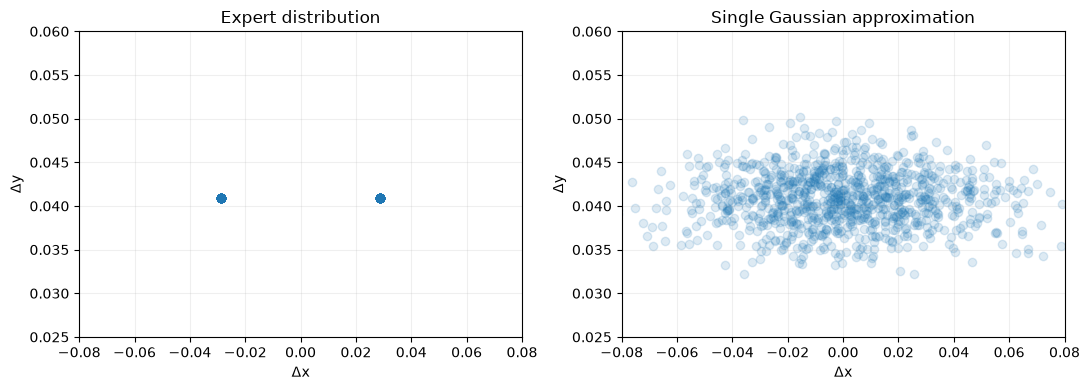

In [10]:
# Sample from the fitted Gaussian distribution
gaussian_actions = rng.multivariate_normal(
    mean=mu,
    cov=cov_regularized,
    size=1000,
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(
    expert_actions[:, 0],
    expert_actions[:, 1],
    alpha=0.15,
)
axes[0].set_title("Expert distribution")

axes[1].scatter(
    gaussian_actions[:, 0],
    gaussian_actions[:, 1],
    alpha=0.15,
)
axes[1].set_title("Single Gaussian approximation")

for ax in axes:
    ax.set_xlim(-0.08, 0.08)
    ax.set_ylim(0.025, 0.06)
    ax.set_xlabel("Δx")
    ax.set_ylabel("Δy")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Probability density

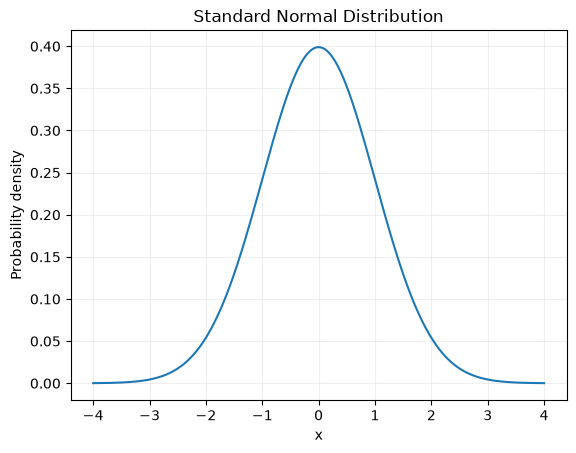

Sample: tensor(-0.6070)
Mean: tensor(0.)
Log density at x=0: tensor(-0.9189)


In [12]:
import torch
from torch.distributions import Normal

dist = Normal(
    loc=torch.tensor(0.0),
    scale=torch.tensor(1.0),
)

x = torch.linspace(-4, 4, 500)

density = torch.exp(dist.log_prob(x))

plt.plot(x.numpy(), density.numpy())
plt.xlabel("x")
plt.ylabel("Probability density")
plt.title("Standard Normal Distribution")
plt.grid(alpha=0.2)
plt.show()

print("Sample:", dist.sample())
print("Mean:", dist.mean)
print("Log density at x=0:", dist.log_prob(torch.tensor(0.0)))

---

## probabilistic learning con PyTorch

In [ ]:
torch.manual_seed(42)

# X ~ N(2,0.5^2)
data = torch.randn(1000) * 0.5 + 2.0

In [14]:
# gradient descent

mu = torch.nn.Parameter(torch.tensor(0.0))

optimizer = torch.optim.Adam([mu], lr=0.05)

loss_history = []

for epoch in range(200):
    dist = Normal(loc=mu, scale=0.5)

    loss = -dist.log_prob(data).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

print("Learned mean:", mu.item())
print("Empirical mean:", data.mean().item())

Learned mean: 2.0020499229431152
Empirical mean: 2.002115488052368


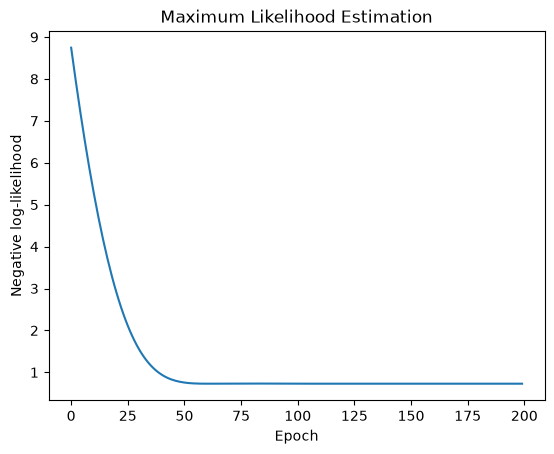

In [15]:
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Negative log-likelihood")
plt.title("Maximum Likelihood Estimation")
plt.show()

## Mixture of Gaussians

A single Gaussian is unimodal: it has only one peak.

A Mixture of Gaussians (MoG) combines multiple Gaussian distributions:

$$
p(a)=\sum_{k=1}^{K}w_k\,\mathcal N(a;\mu_k,\Sigma_k)
$$

where:

- $K$ is the number of components.
- $w_k$ is the probability of selecting component $k$.
- $\mu_k$ is the mean of component $k$.
- $\Sigma_k$ is its covariance matrix.

The weights satisfy:

$$
w_k\geq0,\qquad\sum_k w_k=1.
$$

Sampling consists of selecting a component and then sampling
an action from that component.

In [17]:
import torch
import matplotlib.pyplot as plt

from torch.distributions import (
    Normal,
    Categorical,
    MixtureSameFamily,
    Independent,
)

means = torch.tensor([
    [-0.02867, 0.04096],  # left
    [ 0.02867, 0.04096],  # right
])

stds = torch.full_like(means, 0.003)

weights = torch.tensor([0.5, 0.5])



# Mixture of Gaussians in torch
components = Independent(
    Normal(loc=means, scale=stds),
    reinterpreted_batch_ndims=1,
)

mixture = MixtureSameFamily(
    mixture_distribution=Categorical(probs=weights),
    component_distribution=components,
)

In [18]:
samples = mixture.sample((1000,))

print(samples.shape)
print(mixture.mean)

torch.Size([1000, 2])
tensor([0.0000, 0.0410])


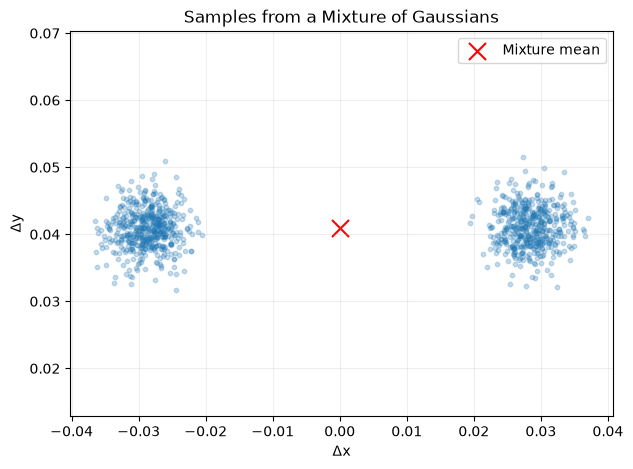

In [19]:
plt.figure(figsize=(7, 5))

plt.scatter(
    samples[:, 0].numpy(),
    samples[:, 1].numpy(),
    alpha=0.25,
    s=10,
)

plt.scatter(
    *mixture.mean.numpy(),
    color="red",
    marker="x",
    s=150,
    label="Mixture mean",
)

plt.xlabel("Δx")
plt.ylabel("Δy")
plt.title("Samples from a Mixture of Gaussians")
plt.legend()
plt.axis("equal")
plt.grid(alpha=0.2)
plt.show()

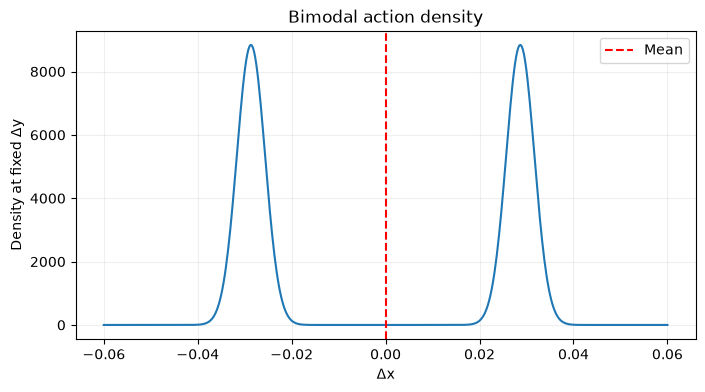

In [20]:
x = torch.linspace(-0.06, 0.06, 500)

actions = torch.stack([
    x,
    torch.full_like(x, 0.04096),
], dim=-1)

log_density = mixture.log_prob(actions)
density = torch.exp(log_density)

plt.figure(figsize=(8, 4))

plt.plot(x.numpy(), density.numpy())

plt.axvline(
    0.0,
    color="red",
    linestyle="--",
    label="Mean",
)

plt.xlabel("Δx")
plt.ylabel("Density at fixed Δy")
plt.title("Bimodal action density")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Mixture Density Network (MDN)

In [21]:
import torch.nn as nn
import torch.nn.functional as F


class MDNPolicy(nn.Module):
    def __init__(
        self,
        obs_dim=4,
        action_dim=2,
        n_components=2,
        hidden_dim=64,
    ):
        super().__init__()

        self.n_components = n_components
        self.action_dim = action_dim

        self.encoder = nn.Sequential(
            nn.Linear(obs_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )

        self.logits_head = nn.Linear(
            hidden_dim, n_components
        )

        self.mean_head = nn.Linear(
            hidden_dim, n_components * action_dim
        )

        self.scale_head = nn.Linear(
            hidden_dim, n_components * action_dim
        )

    def forward(self, observations):
        h = self.encoder(observations)

        logits = self.logits_head(h)

        means = self.mean_head(h).reshape(
            -1, self.n_components, self.action_dim
        )

        scales = F.softplus(
            self.scale_head(h)
        ).reshape(
            -1, self.n_components, self.action_dim
        ) + 1e-4

        components = Independent(
            Normal(loc=means, scale=scales),
            1,
        )

        return MixtureSameFamily(
            Categorical(logits=logits),
            components,
        )

In [22]:
model = MDNPolicy()

observation = torch.tensor(
    [[0.0, 0.0, 0.0, 1.0]],
    dtype=torch.float32,
)

dist = model(observation)

print("Sample:", dist.sample())
print("Mean:", dist.mean)

Sample: tensor([[1.3404, 0.1075]])
Mean: tensor([[-0.0117,  0.0900]], grad_fn=<SumBackward1>)


In [23]:
torch.manual_seed(42)

fixed_observations = torch.tensor(
    np.tile(
        [0.0, 0.0, 0.0, 1.0],
        (len(expert_actions), 1),
    ),
    dtype=torch.float32,
)

fixed_actions = torch.tensor(
    expert_actions,
    dtype=torch.float32,
)

In [24]:
# Train the MDN policy on the expert actions
model = MDNPolicy()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
)

loss_history = []

for epoch in range(500):
    dist = model(fixed_observations)

    loss = -dist.log_prob(fixed_actions).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch+1}: "
            f"NLL = {loss.item():.4f}"
        )

Epoch 100: NLL = -5.1278
Epoch 200: NLL = -6.8074
Epoch 300: NLL = -6.6648
Epoch 400: NLL = -7.0777
Epoch 500: NLL = -6.2694


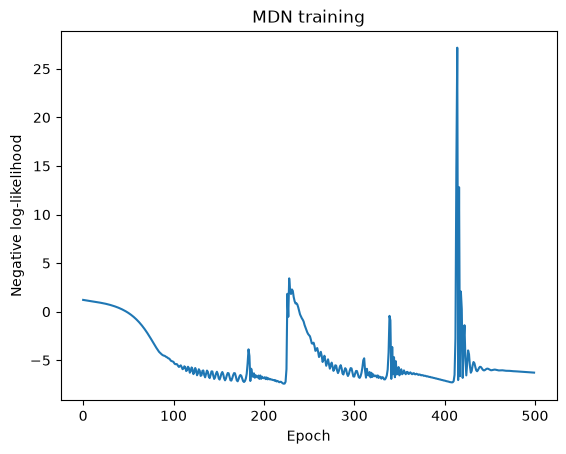

In [25]:
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Negative log-likelihood")
plt.title("MDN training")
plt.show()

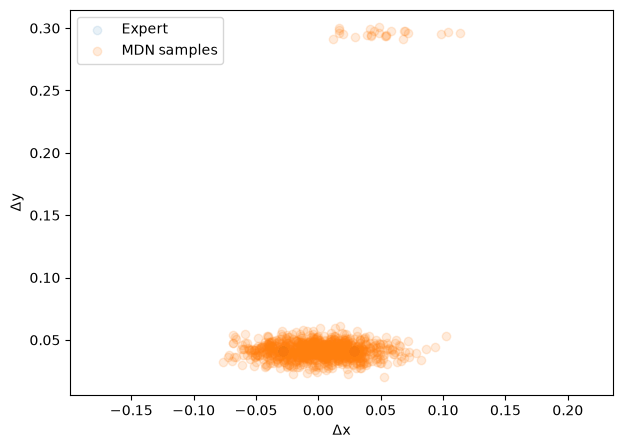

In [26]:
with torch.no_grad():
    observation = fixed_observations[:1]

    learned_dist = model(observation)

    samples = learned_dist.sample((1000,))[:, 0, :]

plt.figure(figsize=(7, 5))

plt.scatter(
    fixed_actions[:, 0],
    fixed_actions[:, 1],
    alpha=0.1,
    label="Expert",
)

plt.scatter(
    samples[:, 0],
    samples[:, 1],
    alpha=0.15,
    label="MDN samples",
)

plt.xlabel("Δx")
plt.ylabel("Δy")
plt.legend()
plt.axis("equal")
plt.show()

In [27]:
with torch.no_grad():
    dist = model(fixed_observations[:1])

    weights = dist.mixture_distribution.probs
    means = dist.component_distribution.base_dist.loc
    scales = dist.component_distribution.base_dist.scale

print("Weights:\n", weights)
print("Means:\n", means)
print("Scales:\n", scales)

Weights:
 tensor([[0.0281, 0.9719]])
Means:
 tensor([[[ 5.1141e-02,  2.9608e-01],
         [-1.5309e-04,  4.1145e-02]]])
Scales:
 tensor([[[0.0364, 0.0035],
         [0.0286, 0.0061]]])


In [28]:
class FixedScaleMDN(nn.Module):
    def __init__(
        self,
        obs_dim=4,
        action_dim=2,
        n_components=2,
        hidden_dim=64,
        scale=0.003,
    ):
        super().__init__()

        self.n_components = n_components
        self.action_dim = action_dim
        self.scale = scale

        self.encoder = nn.Sequential(
            nn.Linear(obs_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )

        self.logits_head = nn.Linear(
            hidden_dim,
            n_components,
        )

        self.mean_head = nn.Linear(
            hidden_dim,
            n_components * action_dim,
        )

    def forward(self, observations):
        h = self.encoder(observations)

        logits = self.logits_head(h)

        means = self.mean_head(h).reshape(
            -1,
            self.n_components,
            self.action_dim,
        )

        components = Independent(
            Normal(
                loc=means,
                scale=torch.full_like(means, self.scale),
            ),
            1,
        )

        return MixtureSameFamily(
            Categorical(logits=logits),
            components,
        )


torch.manual_seed(42)

model = FixedScaleMDN(scale=0.003)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,
)

loss_history = []

for epoch in range(1000):
    dist = model(fixed_observations)

    loss = -dist.log_prob(fixed_actions).mean()

    optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0,
    )

    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch+1:4d} | "
            f"NLL: {loss.item():.4f}"
        )

Epoch  100 | NLL: -9.0830
Epoch  200 | NLL: -9.0865
Epoch  300 | NLL: -9.0869
Epoch  400 | NLL: -9.0869
Epoch  500 | NLL: -9.0869
Epoch  600 | NLL: -9.0870
Epoch  700 | NLL: -9.0870
Epoch  800 | NLL: -9.0870
Epoch  900 | NLL: -9.0869
Epoch 1000 | NLL: -9.0869


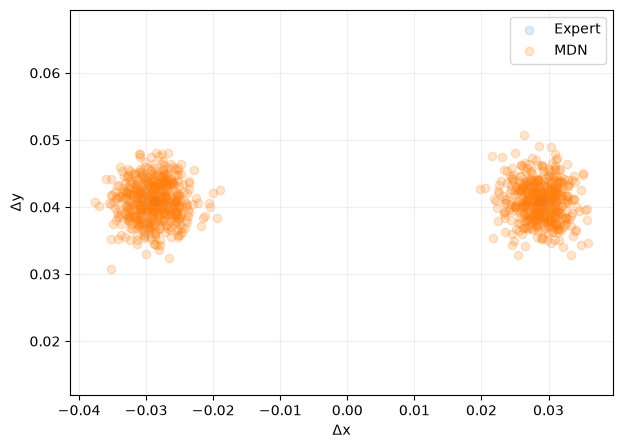

In [29]:
with torch.no_grad():
    learned_dist = model(fixed_observations[:1])

    samples = learned_dist.sample((1000,))[:, 0, :]

plt.figure(figsize=(7, 5))

plt.scatter(
    fixed_actions[:, 0],
    fixed_actions[:, 1],
    alpha=0.15,
    label="Expert",
)

plt.scatter(
    samples[:, 0],
    samples[:, 1],
    alpha=0.2,
    label="MDN",
)

plt.xlabel("Δx")
plt.ylabel("Δy")
plt.legend()
plt.axis("equal")
plt.grid(alpha=0.2)
plt.show()

## Conditional Mixture Density Network

We now train a Mixture Density Network on the complete PointRobot
demonstration dataset.

Unlike the previous experiment, observations are no longer fixed.

The model learns:

$$
p_\theta(a_t \mid o_t)
$$

We will evaluate the policy in closed-loop and compare it with
deterministic Behavior Cloning.

Our hypothesis is that modeling multiple action modes can improve
the representation of expert behavior, but independent action sampling
may introduce temporal inconsistency.

In [31]:
from torch.utils.data import TensorDataset, DataLoader

demonstrations = collect_demonstrations(
    n_episodes=500,
    seed=42,
)

observations = np.concatenate([
    demo["observations"]
    for demo in demonstrations
])

actions = np.concatenate([
    demo["actions"]
    for demo in demonstrations
])

x = torch.tensor(observations, dtype=torch.float32)
y = torch.tensor(actions, dtype=torch.float32)

dataset = TensorDataset(x, y)

dataloader = DataLoader(
    dataset,
    batch_size=256,
    shuffle=True,
)

print("Observations:", x.shape)
print("Actions:", y.shape)

Observations: torch.Size([12768, 4])
Actions: torch.Size([12768, 2])


Epoch  20 | NLL: -8.1842
Epoch  40 | NLL: -8.7336
Epoch  60 | NLL: -9.0868
Epoch  80 | NLL: -9.2727
Epoch 100 | NLL: -9.3790
Epoch 120 | NLL: -9.4395
Epoch 140 | NLL: -9.4733
Epoch 160 | NLL: -9.5084
Epoch 180 | NLL: -9.5089
Epoch 200 | NLL: -9.5059


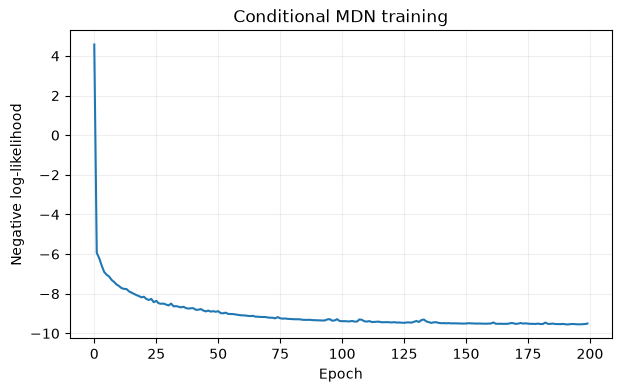

In [32]:
torch.manual_seed(42)

mdn_policy = FixedScaleMDN(
    obs_dim=4,
    action_dim=2,
    n_components=2,
    hidden_dim=64,
    scale=0.003,
)

optimizer = torch.optim.Adam(
    mdn_policy.parameters(),
    lr=1e-3,
)

num_epochs = 200
loss_history = []

for epoch in range(num_epochs):
    epoch_loss = 0.0

    for batch_obs, batch_actions in dataloader:
        dist = mdn_policy(batch_obs)

        loss = -dist.log_prob(batch_actions).mean()

        optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            mdn_policy.parameters(),
            max_norm=1.0,
        )

        optimizer.step()

        epoch_loss += loss.item() * len(batch_obs)

    epoch_loss /= len(dataset)
    loss_history.append(epoch_loss)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch+1:3d} | "
            f"NLL: {epoch_loss:.4f}"
        )

plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Negative log-likelihood")
plt.title("Conditional MDN training")
plt.grid(alpha=0.2)
plt.show()

In [33]:
test_obs = torch.tensor(
    [[0.0, 0.0, 0.0, 1.0]],
    dtype=torch.float32,
)

mdn_policy.eval()

with torch.no_grad():
    dist = mdn_policy(test_obs)

    weights = dist.mixture_distribution.probs[0]
    means = dist.component_distribution.base_dist.loc[0]

    samples = dist.sample((1000,))[:, 0, :]

print("Weights:", weights.numpy())
print("Means:\n", means.numpy())
print("Mixture mean:", dist.mean[0].numpy())

Weights: [0.5109513  0.48904866]
Means:
 [[ 0.02834522  0.03944617]
 [-0.02826838  0.04059571]]
Mixture mean: [0.00065841 0.04000835]


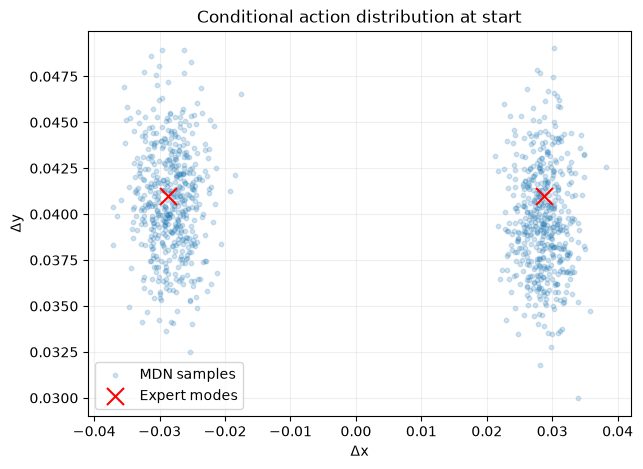

In [34]:
start = np.array([0.0, 0.0])
goal = np.array([0.0, 1.0])

a_left = left_expert(start, goal)
a_right = right_expert(start, goal)

plt.figure(figsize=(7, 5))

plt.scatter(
    samples[:, 0],
    samples[:, 1],
    alpha=0.2,
    s=10,
    label="MDN samples",
)

plt.scatter(
    [a_left[0], a_right[0]],
    [a_left[1], a_right[1]],
    color="red",
    marker="x",
    s=150,
    label="Expert modes",
)

plt.xlabel("Δx")
plt.ylabel("Δy")
plt.title("Conditional action distribution at start")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [35]:
# Function for rollout

def stochastic_mdn_policy(position, goal):
    observation = np.concatenate([
        position,
        goal,
    ])

    observation = torch.tensor(
        observation,
        dtype=torch.float32,
    ).unsqueeze(0)

    with torch.no_grad():
        dist = mdn_policy(observation)
        action = dist.sample()[0]

    return action.numpy()

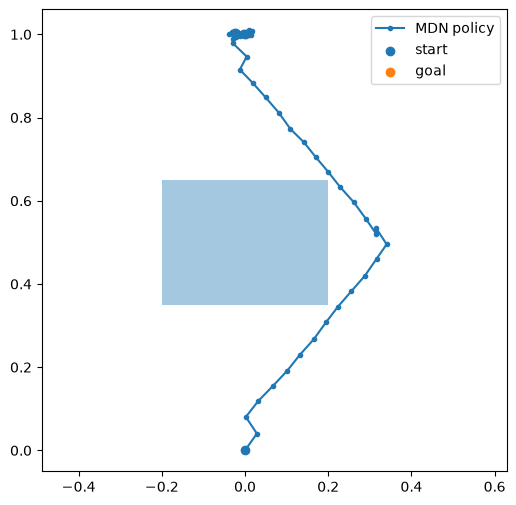

In [39]:
from robot_learning_playground.point_robot import rollout
from robot_learning_playground.point_robot import OBSTACLE

START = np.array([0.0, 0.0])
GOAL = np.array([0.0, 1.0])

trajectory = rollout(
    stochastic_mdn_policy,
    START,
    GOAL,
)

positions = trajectory["positions"]

plt.figure(figsize=(6, 6))

plt.plot(
    positions[:, 0],
    positions[:, 1],
    "-o",
    markersize=3,
    label="MDN policy",
)

rect = plt.Rectangle(
    (OBSTACLE["xmin"], OBSTACLE["ymin"]),
    OBSTACLE["xmax"] - OBSTACLE["xmin"],
    OBSTACLE["ymax"] - OBSTACLE["ymin"],
    alpha=0.4,
)

plt.gca().add_patch(rect)

plt.scatter(*START, label="start")
plt.scatter(*GOAL, label="goal")

plt.axis("equal")
plt.legend()
plt.show()

### Evalaution on 100 rollout

In [40]:
from robot_learning_playground.point_robot import (
    is_collision,
    reached_goal,
    sample_task,
    rollout,
)

def evaluate_trajectory(trajectory, goal, tolerance=0.05):
    positions = trajectory["positions"]

    collision = any(
        is_collision(position)
        for position in positions
    )

    reached = any(
        reached_goal(position, goal, tolerance)
        for position in positions
    )

    return {
        "success": reached and not collision,
        "collision": collision,
    }

In [43]:
rng = np.random.default_rng(123)

trajectories = []
results = []

for _ in range(100):
    start, goal = sample_task(rng)

    trajectory = rollout(
        stochastic_mdn_policy,
        start,
        goal,
        goal_tolerance=0.05
    )

    result = evaluate_trajectory(
        trajectory,
        goal,
    )

    trajectories.append(trajectory)
    results.append(result)

success_rate = np.mean([
    r["success"] for r in results
])

collision_rate = np.mean([
    r["collision"] for r in results
])

print(f"MDN success rate:   {success_rate:.1%}")
print(f"MDN collision rate: {collision_rate:.1%}")

MDN success rate:   94.0%
MDN collision rate: 5.0%


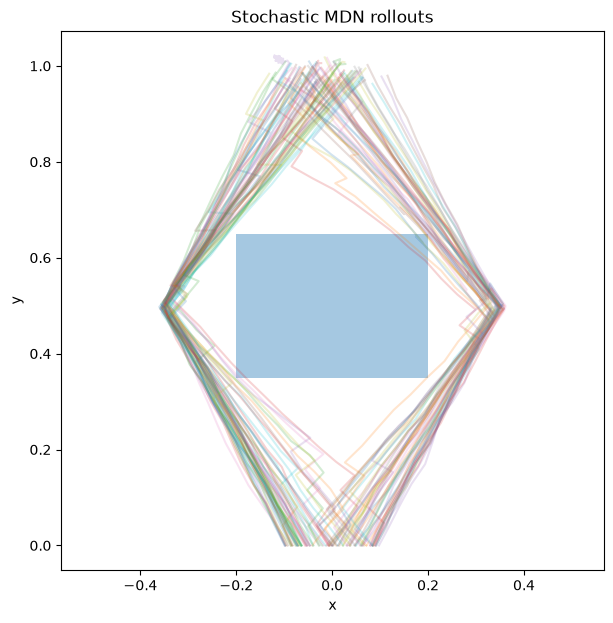

In [44]:
plt.figure(figsize=(7, 7))

for trajectory in trajectories:
    positions = trajectory["positions"]

    plt.plot(
        positions[:, 0],
        positions[:, 1],
        alpha=0.2,
    )

rect = plt.Rectangle(
    (OBSTACLE["xmin"], OBSTACLE["ymin"]),
    OBSTACLE["xmax"] - OBSTACLE["xmin"],
    OBSTACLE["ymax"] - OBSTACLE["ymin"],
    alpha=0.4,
)

plt.gca().add_patch(rect)

plt.xlim(-0.6, 0.6)
plt.ylim(-0.1, 1.2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Stochastic MDN rollouts")
plt.axis("equal")
plt.show()

Horizontal action sign changes: 1


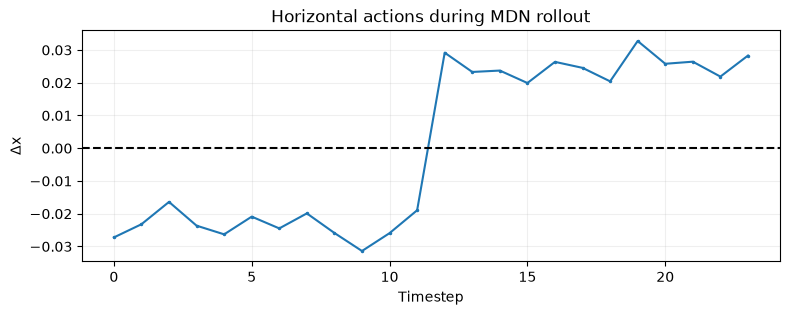

In [45]:
actions = trajectory["actions"]

dx = actions[:, 0]

sign_changes = np.sum(
    np.sign(dx[1:]) != np.sign(dx[:-1])
)

print("Horizontal action sign changes:", sign_changes)

plt.figure(figsize=(9, 3))
plt.plot(dx, marker=".", markersize=3)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Timestep")
plt.ylabel("Δx")
plt.title("Horizontal actions during MDN rollout")
plt.grid(alpha=0.2)
plt.show()

## Conclusions

We investigated probabilistic modeling for robot actions.

Starting from deterministic Behavior Cloning, we introduced:

- Conditional action distributions p(a | o)
- Expectation, variance and covariance
- Gaussian distributions and probability density
- Maximum Likelihood Estimation (MLE)
- Negative Log-Likelihood (NLL)
- Mixture of Gaussians
- Mixture Density Networks (MDN)

Our conditional MDN successfully learned a bimodal action
distribution corresponding to the left and right expert strategies.

Unlike deterministic BC, the MDN can sample actions from
different modes rather than predicting their conditional mean.

Closed-loop rollouts demonstrated that stochastic policies can
produce valid trajectories, but also highlighted the importance
of temporal consistency and termination conditions.

### Key takeaway

Modeling multimodal actions is not the same as modeling
temporally coherent behaviors.

Next, we will extend the prediction target from a single
action to an action sequence:

$$
p(a_t \mid o_t)
\quad\longrightarrow\quad
p(a_{t:t+H-1} \mid o_t)
$$

This introduces action chunking, a key concept behind
modern imitation learning methods such as ACT and
Diffusion Policy.